# 1.0 — Setup & Imports
Mount Google Drive and import all required standard, third-party, and ML libraries.

In [1]:
import os
import sys
from pathlib import Path

IN_KAGGLE = Path("/kaggle").exists()
IN_COLAB  = "google.colab" in sys.modules

if IN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive", force_remount=False)
    except Exception as e:
        print(f"Colab drive mount note: {e}")



Mounted at /content/drive


In [2]:
from scipy.io import loadmat
# Standard library
import io
import json
import os
import random
import time
from pathlib import Path

# Third-party – data / viz
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import ListedColormap
from openpyxl import Workbook, load_workbook
from openpyxl.drawing.image import Image as XLImage
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    log_loss,
)
from sklearn.model_selection import train_test_split

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

sns.set_style("whitegrid")
print("TensorFlow:", tf.__version__)


TensorFlow: 2.20.0


# 2.0 — Configuration
All hyper-parameters, paths, and architecture configs are defined here. Change values in this single cell to reconfigure the whole notebook.

In [3]:
# ── Reproducibility ──────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ── Paths & environment detection ────────────────────────────────────
IN_KAGGLE = Path('/kaggle').exists()
IN_COLAB  = 'google.colab' in sys.modules

if IN_KAGGLE:
    PROJECT_ROOT = Path('/kaggle/working/Classification')
    MODEL_DIR    = PROJECT_ROOT / 'mambahsi' / 'models'
    RESULTS_DIR  = PROJECT_ROOT / 'mambahsi' / 'results'
elif IN_COLAB:
    PROJECT_ROOT = Path('/content/drive/My Drive/Classification')
    MODEL_DIR    = PROJECT_ROOT / 'mambahsi' / 'models'
    RESULTS_DIR  = PROJECT_ROOT / 'mambahsi' / 'results'
else:
    PROJECT_ROOT = Path('.')
    MODEL_DIR    = Path('./models')
    RESULTS_DIR  = Path('./results')

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR    = RESULTS_DIR / "training_plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
VIS_DIR     = RESULTS_DIR / "scene_visualizations"
VIS_DIR.mkdir(parents=True, exist_ok=True)

# Point DATA_DIR to /kaggle/input/dias-dataset-k01 with dynamic glob fallback
mat_candidates = list(Path("/kaggle/input").glob("**/k001.mat")) or list(Path("/kaggle/input").glob("**/DIAS.mat"))
if mat_candidates:
    DATA_DIR = mat_candidates[0].parent
elif Path("data").exists():
    DATA_DIR = Path("data")
else:
    DATA_DIR = Path("/kaggle/input/dias-dataset-k01")

DATA_FILE  = DATA_DIR / "k001.mat" if (DATA_DIR / "k001.mat").exists() else (DATA_DIR / "DIAS.mat" if (DATA_DIR / "DIAS.mat").exists() else DATA_DIR / "k001.mat")
LABEL_FILE = DATA_DIR / "k002.mat" if (DATA_DIR / "k002.mat").exists() else (DATA_DIR / "DIAS_ref.mat" if (DATA_DIR / "DIAS_ref.mat").exists() else DATA_DIR / "k002.mat")


# ── Dataset geometry ──────────────────────────────────────────────────
# H, W, B are inferred automatically from the .mat cube shape
H, W, B     = None, None, None
PERCENTILE_CLIP = (2.0, 98.0)          # height, width, bands
PATCH_SIZE  = 9
INNER_PATCH = 3                   # spatial tokenisation patch size for the SSM token sequence

# ── Train / val / test splits ─────────────────────────────────────────
TRAIN_PERCENT          = 0.75
VAL_SPLIT_FROM_TRAIN   = 0.20

# ── Training ──────────────────────────────────────────────────────────
BATCH_SIZE    = 128
EPOCHS        = 100
LEARNING_RATE = 3e-4
DROPOUT_RATE  = 0.25
CAPACITY_PRESET = "mambahsi_arch"

TRAIN_CFG = {
    "label_smoothing": 0.05,
    "weight_decay":    1e-4,
    "clipnorm":        1.0,
    "cosine_alpha":    0.05,
}

# ── AlexNet legacy recipe — kept verbatim from the original notebook per the
# "copy training loop verbatim" requirement. NOTE: this is now DEAD CODE. None
# of the three MambaHSI variants below is named "AlexNet_CNN", so the
# model_name == "AlexNet_CNN" branch inside train_save_evaluate (Section 5.3)
# never fires and these constants / x_train_alex / _alexnet_legacy_lr are
# unused. Safe to delete if you want a cleaner notebook. ───────────────
ALEXNET_LEGACY_SPLIT_SEED   = 10
ALEXNET_LEGACY_TRAIN_PERCENT = 0.75
ALEXNET_LR_START = 0.01
ALEXNET_LR_MAX   = 0.02
ALEXNET_LR_MIN   = 0.005

# ── Architecture configs ──────────────────────────────────────────────
# MambaHSI-style spatial-spectral state-space model, three capacities.
# Hyperparameter reasoning (dataset: 9x9x6 patches, ~a few thousand labelled
# samples, 7 classes — see markdown note in Section 4.3 for more detail):
#   Small — 2 SSM blocks,  state_dim=64,  hidden_dim=128, mlp_ratio=2
#   Base  — 4 SSM blocks,  state_dim=128, hidden_dim=256, mlp_ratio=4
#   Large — 6 SSM blocks,  state_dim=192, hidden_dim=384, mlp_ratio=4
MAMBAHSI_SMALL_CFG = {"inner_patch": 3, "hidden_dim": 128, "state_dim": 64,  "num_blocks": 2, "mlp_ratio": 2}
MAMBAHSI_BASE_CFG  = {"inner_patch": 3, "hidden_dim": 256, "state_dim": 128, "num_blocks": 4, "mlp_ratio": 4}
MAMBAHSI_LARGE_CFG = {"inner_patch": 3, "hidden_dim": 384, "state_dim": 192, "num_blocks": 6, "mlp_ratio": 4}

# Fallback configs used when Colab runs out of memory (mirrors the original
# GFNET_FALLBACK_CFG / VIT_FALLBACK_CFG pattern — only the two larger variants
# get a fallback, matching how the original small/simple AlexNet backbone
# never needed one).
MAMBAHSI_BASE_FALLBACK_CFG  = {"inner_patch": 3, "hidden_dim": 192, "state_dim": 96,  "num_blocks": 3, "mlp_ratio": 4}
MAMBAHSI_LARGE_FALLBACK_CFG = {"inner_patch": 3, "hidden_dim": 256, "state_dim": 128, "num_blocks": 4, "mlp_ratio": 4}

# ── Visualisation palette ─────────────────────────────────────────────
CLASS_COLOR_BASE = [
    "#0000FF", "#00FF00", "#FF0000", "#00FFFF", "#FF00FF",
    "#FFFF00", "#A52A2A", "#FFA500", "#7FFF00", "#8A2BE2",
]
BACKGROUND_COLOR  = "#000000"
VIS_EXCEL_PATH    = VIS_DIR / "initial_classification_maps.xlsx"

print("Data file:    ", DATA_FILE)
print("Label file:   ", LABEL_FILE)
print("Model dir:    ", MODEL_DIR)
print("Results dir:  ", RESULTS_DIR)
print("Plot dir:     ", PLOT_DIR)
print("Arch preset:  ", CAPACITY_PRESET)



Data file:     /content/drive/My Drive/Classification/data/data.csv
Label file:    /content/drive/My Drive/Classification/data/ref.csv
Model dir:     /content/drive/My Drive/Classification/mambahsi/models
Results dir:   /content/drive/My Drive/Classification/mambahsi/results
Plot dir:      /content/drive/My Drive/Classification/mambahsi/results/training_plots
Arch preset:   mambahsi_arch


# 3.0 — Data Loading & Preprocessing
Load the raw multispectral CSV files, apply per-band min-max normalisation, extract labelled patches, and create stratified train / val / test splits.

## 3.1 — Loading and patch extraction helpers

In [4]:
def load_scene_from_mat(data_path, label_path, data_key=None, label_key=None):
    """Load a hyperspectral/multispectral scene + reference labels from .mat files.

    Works for any band count / scene size (previously hard-coded to 6-band CSV
    scenes). If data_key / label_key are not given, the first non-metadata
    variable in each .mat file is used automatically — this matches files
    such as DIAS.mat / DIAS_ref.mat where the array is stored under a single
    named variable. Each spectral band is robustly stretched to [0, 1] using
    a percentile clip (see PERCENTILE_CLIP) rather than literal min/max.
    """
    data_mat  = loadmat(data_path)
    label_mat = loadmat(label_path)

    def _first_array(mat_dict, key):
        if key is not None:
            return mat_dict[key]
        candidates = [v for k, v in mat_dict.items() if not k.startswith("__")]
        if not candidates:
            raise ValueError(f"No data arrays found in {mat_dict.keys()}")
        return candidates[0]

    x = _first_array(data_mat, data_key).astype(np.float32)
    y = _first_array(label_mat, label_key).astype(np.int32)

    if x.ndim != 3:
        raise ValueError(f"Expected a (H, W, Bands) cube, got shape {x.shape}")
    if y.shape != x.shape[:2]:
        raise ValueError(f"Label shape {y.shape} does not match image shape {x.shape[:2]}")

    height, width, bands = x.shape

    # Robust per-band stretch: clip to the [lower_pct, upper_pct] percentile
    # range before min-max scaling, instead of literal min/max. A handful of
    # saturated/no-data pixels (e.g. sensor clipping at the int8 range limits
    # -128/127) would otherwise dominate the stretch and crush the dynamic
    # range of the rest of the scene.
    x_norm = np.empty_like(x, dtype=np.float32)
    for b in range(bands):
        band = x[:, :, b]
        lo   = np.percentile(band, PERCENTILE_CLIP[0])
        hi   = np.percentile(band, PERCENTILE_CLIP[1])
        denom = max(hi - lo, 1e-8)
        band_clipped = np.clip(band, lo, hi)
        x_norm[:, :, b] = (band_clipped - lo) / denom

    return x_norm, y, height, width, bands


def extract_labeled_patches(x, y, patch_size=9):
    """Extract (patch_size × patch_size) spatial patches around every labelled pixel."""
    pad   = patch_size // 2
    x_pad = np.pad(x, ((pad, pad), (pad, pad), (0, 0)), mode="edge")

    coords  = np.argwhere(y > 0)
    patches = np.empty((coords.shape[0], patch_size, patch_size, x.shape[-1]), dtype=np.float32)
    labels  = np.empty((coords.shape[0],), dtype=np.int32)

    for i, (r, c) in enumerate(coords):
        patches[i] = x_pad[r:r + patch_size, c:c + patch_size, :]
        labels[i]  = int(y[r, c]) - 1  # convert class IDs to 0..C-1

    return patches, labels, coords



## 3.2 — Load data and create splits

In [5]:
x_img, y_img, H, W, B = load_scene_from_mat(DATA_FILE, LABEL_FILE)
X, y, coords = extract_labeled_patches(x_img, y_img, PATCH_SIZE)

num_classes = int(np.unique(y).size)
input_shape = (PATCH_SIZE, PATCH_SIZE, B)

print("x_img:", x_img.shape, "  y_img:", y_img.shape)
print("Labelled samples:", X.shape[0])
print("Patch tensor:    ", X.shape)
print("Num classes:     ", num_classes)


x_img: (330, 307, 6)   y_img: (330, 307)
Labelled samples: 17239
Patch tensor:     (17239, 9, 9, 6)
Num classes:      7


In [6]:
# Primary stratified split used by all three MambaHSI variants
x_train_full, x_test, y_train_full, y_test = train_test_split(
    X, y,
    train_size=TRAIN_PERCENT,
    random_state=SEED,
    stratify=y,
)
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full,
    test_size=VAL_SPLIT_FROM_TRAIN,
    random_state=SEED,
    stratify=y_train_full,
)

y_train_cat = keras.utils.to_categorical(y_train, num_classes)
y_val_cat   = keras.utils.to_categorical(y_val,   num_classes)
y_test_cat  = keras.utils.to_categorical(y_test,  num_classes)

print("Train:", x_train.shape, y_train.shape)
print("Val:  ", x_val.shape,   y_val.shape)
print("Test: ", x_test.shape,  y_test.shape)


Train: (10343, 9, 9, 6) (10343,)
Val:   (2586, 9, 9, 6) (2586,)
Test:  (4310, 9, 9, 6) (4310,)


In [7]:
# AlexNet legacy split — matches the original single-head notebook for
# uncertainty recovery (different seed and no val split)
x_train_alex, x_test_alex, y_train_alex, y_test_alex = train_test_split(
    X, y,
    train_size=ALEXNET_LEGACY_TRAIN_PERCENT,
    random_state=ALEXNET_LEGACY_SPLIT_SEED,
    stratify=y,
)
y_train_alex_cat = keras.utils.to_categorical(y_train_alex, num_classes)
y_test_alex_cat  = keras.utils.to_categorical(y_test_alex,  num_classes)

print("AlexNet Train:", x_train_alex.shape, y_train_alex.shape)
print("AlexNet Test: ", x_test_alex.shape,  y_test_alex.shape)


AlexNet Train: (12929, 9, 9, 6) (12929,)
AlexNet Test:  (4310, 9, 9, 6) (4310,)


# 4.0 — Model Definitions
Defines three capacities of a MambaHSI-style spatial-spectral state-space model (Small / Base / Large). Custom Keras layers are registered for serialisation, following the same pattern used by the backbones this replaces.

## 4.1 — Shared custom Keras layers (PatchExtractor, PatchPositionEncoder)

In [8]:
@tf.keras.utils.register_keras_serializable()
class PatchExtractor(layers.Layer):
    """Extract non-overlapping spatial patches from an image tensor."""

    def __init__(self, patch_size=3, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, images):
        patches     = tf.image.extract_patches(
            images=images,
            sizes=[1, self.patch_size, self.patch_size, 1],
            strides=[1, self.patch_size, self.patch_size, 1],
            rates=[1, 1, 1, 1],
            padding="VALID",
        )
        batch       = tf.shape(images)[0]
        num_patches = tf.shape(patches)[1] * tf.shape(patches)[2]
        patch_dim   = tf.shape(patches)[-1]
        return tf.reshape(patches, [batch, num_patches, patch_dim])

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"patch_size": self.patch_size})
        return cfg


@tf.keras.utils.register_keras_serializable()
class PatchPositionEncoder(layers.Layer):
    """Project patches to embedding dim and add learned positional embeddings."""

    def __init__(self, num_patches, projection_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_patches      = num_patches
        self.projection_dim   = projection_dim
        self.projection       = layers.Dense(projection_dim)
        self.position_embedding = layers.Embedding(input_dim=num_patches, output_dim=projection_dim)

    def call(self, patches):
        positions = tf.range(start=0, limit=self.num_patches, delta=1)
        return self.projection(patches) + self.position_embedding(positions)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"num_patches": self.num_patches, "projection_dim": self.projection_dim})
        return cfg



## 4.2 — MambaHSI selective state-space layers (SpectralScanLayer, SelectiveSSMBlock)

**Implementation note / simplification.** The original Mamba (Gu & Dao, 2023) selective-scan runs as a hardware-aware fused CUDA kernel with fully input-dependent (Δ, A, B, C) parameters. TensorFlow/Keras has no equivalent fused primitive, so `SpectralScanLayer` below approximates the *core idea* — input-dependent (selective) state propagation along a sequence — with a diagonal linear state-space recurrence (S4/S5-style) whose gating signal is computed from the input at every step via `tf.scan`. This is a faithful-in-spirit, not bit-exact, port of the selective-scan mechanism, and is documented again in the layer's own docstring.

In [9]:
@tf.keras.utils.register_keras_serializable()
class SpectralScanLayer(layers.Layer):
    """Simplified structured state-space scan (S4/S5-style diagonal linear
    recurrence) approximating Mamba's selective-scan mechanism in pure Keras ops.

    SIMPLIFICATION FROM TRUE MAMBA: the original selective-scan uses a fused
    CUDA kernel with fully input-dependent (Delta, A, B, C) parameters. There is
    no equivalent fused op in TensorFlow/Keras, so here the "selective" part is
    approximated with a single input-dependent gate applied before a per-channel
    diagonal linear recurrence, evaluated with tf.scan over the sequence axis.
    """

    def __init__(self, state_dim, **kwargs):
        super().__init__(**kwargs)
        self.state_dim = state_dim

    def build(self, input_shape):
        channels = int(input_shape[-1])
        self.in_proj   = layers.Dense(self.state_dim, name="ssm_in_proj")
        self.gate_proj = layers.Dense(self.state_dim, activation="sigmoid", name="ssm_gate_proj")
        self.log_decay = self.add_weight(
            name="log_decay", shape=(self.state_dim,),
            initializer=keras.initializers.RandomUniform(-3.0, -1.0), trainable=True,
        )
        self.out_proj = layers.Dense(channels, name="ssm_out_proj")
        super().build(input_shape)

    def call(self, x):
        # x: (batch, seq, channels)
        decay       = tf.nn.sigmoid(self.log_decay)   # (state_dim,) constrained to (0, 1)
        u           = self.in_proj(x)                  # (batch, seq, state_dim)
        gate        = self.gate_proj(x)                 # (batch, seq, state_dim) — input-dependent selection
        gated_input = u * gate

        scan_input = tf.transpose(gated_input, [1, 0, 2])  # (seq, batch, state_dim)

        def step(prev_state, cur_input):
            return decay * prev_state + cur_input

        init_state = tf.zeros_like(scan_input[0])
        states = tf.scan(step, scan_input, initializer=init_state)  # (seq, batch, state_dim)
        states = tf.transpose(states, [1, 0, 2])                     # (batch, seq, state_dim)
        return self.out_proj(states)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"state_dim": self.state_dim})
        return cfg


@tf.keras.utils.register_keras_serializable()
class SelectiveSSMBlock(layers.Layer):
    """One MambaHSI-style block: a bidirectional selective-scan (forward +
    reverse SpectralScanLayer passes, since spatial patches — unlike causal
    language sequences — benefit from non-causal context) followed by a
    two-layer GELU MLP, both wrapped in pre-LN residual connections. Mirrors
    the residual/MLP pattern used by the `gf_block` helper this replaces.
    """

    def __init__(self, state_dim, hidden_dim, mlp_ratio=4, dropout_rate=0.25, **kwargs):
        super().__init__(**kwargs)
        self.state_dim    = state_dim
        self.hidden_dim   = hidden_dim
        self.mlp_ratio    = mlp_ratio
        self.dropout_rate = dropout_rate

    def build(self, input_shape):
        self.ln1         = layers.LayerNormalization()
        self.scan_fwd     = SpectralScanLayer(self.state_dim)
        self.scan_bwd     = SpectralScanLayer(self.state_dim)
        self.merge_proj   = layers.Dense(self.hidden_dim)
        self.ln2          = layers.LayerNormalization()
        self.mlp1         = layers.Dense(self.hidden_dim * self.mlp_ratio, activation=tf.keras.activations.gelu)
        self.drop1        = layers.Dropout(self.dropout_rate)
        self.mlp2         = layers.Dense(self.hidden_dim, activation=tf.keras.activations.gelu)
        self.drop2        = layers.Dropout(self.dropout_rate)
        super().build(input_shape)

    def call(self, x, training=None):
        y   = self.ln1(x)
        fwd = self.scan_fwd(y)
        bwd = tf.reverse(self.scan_bwd(tf.reverse(y, axis=[1])), axis=[1])
        y   = self.merge_proj(tf.concat([fwd, bwd], axis=-1))
        x   = x + y

        y = self.ln2(x)
        y = self.mlp1(y)
        y = self.drop1(y, training=training)
        y = self.mlp2(y)
        y = self.drop2(y, training=training)
        return x + y

    def get_config(self):
        cfg = super().get_config()
        cfg.update({
            "state_dim": self.state_dim, "hidden_dim": self.hidden_dim,
            "mlp_ratio": self.mlp_ratio, "dropout_rate": self.dropout_rate,
        })
        return cfg



## 4.3 — MambaHSI backbone factory (build_mambahsi)

Tokenises the `(9, 9, 6)` input patch into non-overlapping `INNER_PATCH x INNER_PATCH` spatial tokens (the same tokenisation the original GFNet/ViT backbones used), projects each token to `hidden_dim`, then processes the token sequence with a stack of `SelectiveSSMBlock` state-space blocks before global-average-pooling into a softmax head. Follows the same `build_*(input_shape, num_classes, dropout_rate=0.25, cfg=None)` calling convention as the backbones it replaces, so it plugs into `train_save_evaluate` unchanged.

In [10]:
def build_mambahsi(input_shape, num_classes, dropout_rate=0.25, cfg=None):
    """Build a MambaHSI-style spatial-spectral state-space classifier."""
    cfg = cfg or MAMBAHSI_BASE_CFG
    inner_patch = cfg.get("inner_patch", INNER_PATCH)
    hidden_dim  = cfg["hidden_dim"]
    state_dim   = cfg["state_dim"]
    num_blocks  = cfg["num_blocks"]
    mlp_ratio   = cfg.get("mlp_ratio", 4)
    variant_name = cfg.get("variant_name", "")

    num_patches = (input_shape[0] // inner_patch) * (input_shape[1] // inner_patch)

    inputs = keras.Input(shape=input_shape)
    x      = PatchExtractor(inner_patch, name="mamba_patch_extractor")(inputs)
    x      = PatchPositionEncoder(num_patches, hidden_dim, name="mamba_patch_encoder")(x)
    x      = layers.Dropout(dropout_rate, name="TRAIN_DROPOUT_1")(x)

    for i in range(num_blocks):
        x = SelectiveSSMBlock(
            state_dim, hidden_dim, mlp_ratio, dropout_rate,
            name=f"mamba_ssm_block_{i+1}",
        )(x)

    x = layers.Dropout(dropout_rate, name="TRAIN_DROPOUT_2")(x)
    x = layers.LayerNormalization(name="mamba_final_ln")(x)
    x = layers.GlobalAveragePooling1D(name="mamba_gap")(x)
    x = layers.Flatten(name="mamba_flatten")(x)
    x = layers.Dropout(dropout_rate, name="TRAIN_DROPOUT_3")(x)

    outputs = layers.Dense(num_classes, activation="softmax", name="mamba_logits")(x)
    model_name = f"MambaHSI_{variant_name}" if variant_name else "MambaHSI_SingleHead"
    return keras.Model(inputs, outputs, name=model_name)



# 5.0 — Training & Evaluation Helpers
Optimiser factory, learning-rate schedule, calibration metrics (Brier score, ECE), and the main `train_save_evaluate` function. Copied verbatim from the original notebook — see the note in Section 2.0 about the now-unused AlexNet-specific branch inside `train_save_evaluate`.

## 5.1 — Calibration metrics

In [11]:
def multiclass_brier_score(y_onehot, y_prob):
    """Compute the multiclass Brier score (mean squared error over probability vectors)."""
    return float(np.mean(np.sum((y_prob - y_onehot) ** 2, axis=1)))


def expected_calibration_error(y_true, y_prob, n_bins=15):
    """Compute Expected Calibration Error (ECE) with equal-width confidence bins."""
    confidences = np.max(y_prob, axis=1)
    predictions = np.argmax(y_prob, axis=1)
    correct     = (predictions == y_true).astype(np.float32)
    bin_edges   = np.linspace(0.0, 1.0, n_bins + 1)
    ece         = 0.0

    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i + 1]
        in_bin = (confidences >= lo) & (confidences <= hi if i == n_bins - 1 else confidences < hi)
        prop   = np.mean(in_bin)
        if prop > 0:
            ece += np.abs(np.mean(correct[in_bin]) - np.mean(confidences[in_bin])) * prop

    return float(ece)


## 5.2 — Optimiser factory

In [12]:
def make_optimizer(num_train_samples):
    """Build an AdamW optimiser with a cosine-decay learning-rate schedule."""
    steps_per_epoch = int(np.ceil(num_train_samples / BATCH_SIZE))
    decay_steps     = max(1, steps_per_epoch * EPOCHS)
    lr_schedule     = keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=LEARNING_RATE,
        decay_steps=decay_steps,
        alpha=TRAIN_CFG["cosine_alpha"],
    )
    return keras.optimizers.AdamW(
        learning_rate=lr_schedule,
        weight_decay=TRAIN_CFG["weight_decay"],
        clipnorm=TRAIN_CFG["clipnorm"],
    )


def _alexnet_legacy_lr(epoch):
    """Cosine LR schedule for AlexNet, matching the original single-head script."""
    if EPOCHS <= 1:
        return ALEXNET_LR_START
    phase        = np.pi * epoch / (EPOCHS - 1)
    cosine_decay = 0.5 * (1.0 + np.cos(phase))
    return float((ALEXNET_LR_MAX - ALEXNET_LR_MIN) * cosine_decay + ALEXNET_LR_MIN)


## 5.3 — Main training, saving, and evaluation function

In [13]:
def train_save_evaluate(model_name, model_builder, capacity_tag="max"):
    """Compile, train, save (best + final), and evaluate a single-head model.

    Returns a metrics dict, per-class classification report, confusion matrix,
    and the raw Keras history dict.
    """
    tf.keras.backend.clear_session()
    model     = model_builder()
    best_path  = MODEL_DIR / f"{model_name}_best.keras"
    final_path = MODEL_DIR / f"{model_name}_final.keras"

    # AlexNet uses a legacy Adagrad + cosine LR schedule to match the original
    # single-head script for downstream uncertainty analysis.
    if model_name == "AlexNet_CNN":
        model.compile(
            optimizer=keras.optimizers.Adagrad(learning_rate=ALEXNET_LR_START),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
        )
        callbacks = [
            keras.callbacks.ModelCheckpoint(
                filepath=str(best_path), monitor="val_accuracy",
                mode="max", save_best_only=True, verbose=1,
            ),
            keras.callbacks.LearningRateScheduler(_alexnet_legacy_lr, verbose=0),
        ]
        x_tr, y_tr         = x_train_alex, y_train_alex
        x_va, y_va         = x_test_alex,  y_test_alex
        x_te, y_te, y_te_cat = x_test_alex, y_test_alex, y_test_alex_cat
        x_eval, y_eval, y_eval_cat = x_test_alex, y_test_alex, y_test_alex_cat
        fit_shuffle        = False
    else:
        # GFNet and ViT use AdamW + cosine decay with label smoothing
        model.compile(
            optimizer=make_optimizer(len(x_train)),
            loss=keras.losses.CategoricalCrossentropy(label_smoothing=TRAIN_CFG["label_smoothing"]),
            metrics=["accuracy"],
        )
        callbacks = [
            keras.callbacks.ModelCheckpoint(
                filepath=str(best_path), monitor="val_loss",
                mode="min", save_best_only=True, verbose=1,
            ),
        ]
        x_tr, y_tr         = x_train, y_train_cat
        x_va, y_va         = x_val,   y_val_cat
        x_te, y_te, y_te_cat = x_test, y_test, y_test_cat
        x_eval, y_eval, y_eval_cat = x_val, y_val, y_val_cat
        fit_shuffle        = True

    train_start = time.perf_counter()
    history_obj = model.fit(
        x_tr, y_tr,
        validation_data=(x_va, y_va),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose=1,
        shuffle=fit_shuffle,
    )
    train_time_sec = float(time.perf_counter() - train_start)

    epochs_ran = int(len(history_obj.history.get("loss", [])))
    if epochs_ran != EPOCHS:
        print(f"WARNING: {model_name} ran {epochs_ran} epochs, expected {EPOCHS}.")
    else:
        print(f"{model_name} completed full training: {epochs_ran}/{EPOCHS} epochs.")

    model.save(final_path)

    y_eval_prob = model.predict(x_eval, batch_size=BATCH_SIZE, verbose=0)
    y_test_prob = model.predict(x_te,   batch_size=BATCH_SIZE, verbose=0)
    y_test_pred = np.argmax(y_test_prob, axis=1)

    report = classification_report(y_te, y_test_pred, output_dict=True, zero_division=0)
    cm     = confusion_matrix(y_te, y_test_pred)

    row = {
        "model":            model_name,
        "capacity_tag":     capacity_tag,
        "test_accuracy":    float(accuracy_score(y_te, y_test_pred)),
        "kappa":            float(cohen_kappa_score(y_te, y_test_pred)),
        "macro_f1":         float(f1_score(y_te, y_test_pred, average="macro")),
        "weighted_f1":      float(f1_score(y_te, y_test_pred, average="weighted")),
        "val_nll":          float(log_loss(y_eval, y_eval_prob, labels=np.arange(num_classes))),
        "test_nll":         float(log_loss(y_te,   y_test_prob, labels=np.arange(num_classes))),
        "val_brier":        multiclass_brier_score(y_eval_cat, y_eval_prob),
        "test_brier":       multiclass_brier_score(y_te_cat,   y_test_prob),
        "test_ece_15bin":   expected_calibration_error(y_te, y_test_prob, n_bins=15),
        "epochs_configured": int(EPOCHS),
        "epochs_ran":       epochs_ran,
        "train_time_sec":   train_time_sec,
        "best_model_path":  str(best_path),
        "final_model_path": str(final_path),
    }
    return row, report, cm, history_obj.history


# 6.0 — Model Training
Build factory lambdas, then loop over all three MambaHSI capacities. OOM errors on the Base and Large variants automatically retry with reduced fallback configs (mirrors the original GFNet/ViT fallback behaviour).

In [14]:
def build_mambahsi_with_cfg(cfg, variant_name):
    """Instantiate MambaHSI from a config dict, tagging it with a variant name."""
    cfg = dict(cfg)
    cfg["variant_name"] = variant_name
    return build_mambahsi(input_shape, num_classes, dropout_rate=DROPOUT_RATE, cfg=cfg)


model_builders = {
    "MambaHSI_Small": lambda: build_mambahsi_with_cfg(MAMBAHSI_SMALL_CFG, "Small"),
    "MambaHSI_Base":  lambda: build_mambahsi_with_cfg(MAMBAHSI_BASE_CFG,  "Base"),
    "MambaHSI_Large": lambda: build_mambahsi_with_cfg(MAMBAHSI_LARGE_CFG, "Large"),
}



In [15]:
results_rows   = []
model_artifacts = {}

for model_name, builder in model_builders.items():
    print(f"\n{'=' * 25} Training {model_name} ({CAPACITY_PRESET}) {'=' * 25}")

    try:
        row, report, cm, history = train_save_evaluate(model_name, builder,
                                                       capacity_tag=CAPACITY_PRESET)
    except tf.errors.ResourceExhaustedError:
        # Automatically retry with a smaller fallback config to handle Colab OOM
        if model_name == "MambaHSI_Base":
            print("OOM on MambaHSI_Base config. Retrying with fallback config.")
            tf.keras.backend.clear_session()
            row, report, cm, history = train_save_evaluate(
                model_name, lambda: build_mambahsi_with_cfg(MAMBAHSI_BASE_FALLBACK_CFG, "Base"),
                capacity_tag="fallback",
            )
        elif model_name == "MambaHSI_Large":
            print("OOM on MambaHSI_Large config. Retrying with fallback config.")
            tf.keras.backend.clear_session()
            row, report, cm, history = train_save_evaluate(
                model_name, lambda: build_mambahsi_with_cfg(MAMBAHSI_LARGE_FALLBACK_CFG, "Large"),
                capacity_tag="fallback",
            )
        else:
            raise

    results_rows.append(row)
    model_artifacts[model_name] = {"report": report, "confusion_matrix": cm, "history": history}

summary_df = (
    pd.DataFrame(results_rows)
    .sort_values("test_accuracy", ascending=False)
    .reset_index(drop=True)
)
summary_df




========================= Training MambaHSI_Small (mambahsi_arch) =========================
Epoch 1/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.4997 - loss: 1.4534
Epoch 1: val_loss improved from None to 0.98082, saving model to /content/drive/My Drive/Classification/mambahsi/models/MambaHSI_Small_best.keras

Epoch 1: finished saving model to /content/drive/My Drive/Classification/mambahsi/models/MambaHSI_Small_best.keras
81/81 ━━━━━━━━━━━━━━━━━━━━ 48s 228ms/step - accuracy: 0.5840 - loss: 1.2163 - val_accuracy: 0.7135 - val_loss: 0.9808
Epoch 2/100
78/81 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7075 - loss: 0.9338
Epoch 2: val_loss improved from 0.98082 to 0.89044, saving model to /content/drive/My Drive/Classification/mambahsi/models/MambaHSI_Small_best.keras

Epoch 2: finished saving model to /content/drive/My Drive/Classification/mambahsi/models/MambaHSI_Small_best.keras
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7180 - loss: 0.9119 - val_accuracy: 

,model,capacity_tag,test_accuracy,kappa,macro_f1,weighted_f1,val_nll,test_nll,val_brier,test_brier,test_ece_15bin,epochs_configured,epochs_ran,train_time_sec,best_model_path,final_model_path
0,MambaHSI_Base,mambahsi_arch,0.998376,0.997798,0.998719,0.998375,0.023024,0.023674,0.002545,0.002787,0.020523,100,100,416.761486,/content/drive/My Drive/Classification/mambahs...,/content/drive/My Drive/Classification/mambahs...
1,MambaHSI_Large,mambahsi_arch,0.998144,0.997482,0.998521,0.998142,0.022681,0.022995,0.002228,0.002734,0.019310,100,100,1033.390829,/content/drive/My Drive/Classification/mambahs...,/content/drive/My Drive/Classification/mambahs...
2,MambaHSI_Small,mambahsi_arch,0.997448,0.996539,0.997393,0.997447,0.022058,0.022926,0.004959,0.005357,0.017403,100,100,144.359482,/content/drive/My Drive/Classification/mambahs...,/content/drive/My Drive/Classification/mambahs...


# 7.0 — Results & Metrics
Save classification summaries to CSV / JSON, then plot training curves, cross-model bar charts, calibration proxies, and confusion matrices.

## 7.1 — Save summary CSV and per-model JSON reports

In [16]:
summary_path = RESULTS_DIR / "classification_summary.csv"
summary_df.to_csv(summary_path, index=False)
print("Saved summary:", summary_path)

for model_name, artifact in model_artifacts.items():
    report_path = RESULTS_DIR / f"{model_name}_classification_report.json"
    with open(report_path, "w", encoding="utf-8") as f:
        json.dump(artifact["report"], f, indent=2)

print("Per-model classification reports saved to:", RESULTS_DIR)
summary_df


Saved summary: /content/drive/My Drive/Classification/mambahsi/results/classification_summary.csv
Per-model classification reports saved to: /content/drive/My Drive/Classification/mambahsi/results


,model,capacity_tag,test_accuracy,kappa,macro_f1,weighted_f1,val_nll,test_nll,val_brier,test_brier,test_ece_15bin,epochs_configured,epochs_ran,train_time_sec,best_model_path,final_model_path
0,MambaHSI_Base,mambahsi_arch,0.998376,0.997798,0.998719,0.998375,0.023024,0.023674,0.002545,0.002787,0.020523,100,100,416.761486,/content/drive/My Drive/Classification/mambahs...,/content/drive/My Drive/Classification/mambahs...
1,MambaHSI_Large,mambahsi_arch,0.998144,0.997482,0.998521,0.998142,0.022681,0.022995,0.002228,0.002734,0.019310,100,100,1033.390829,/content/drive/My Drive/Classification/mambahs...,/content/drive/My Drive/Classification/mambahs...
2,MambaHSI_Small,mambahsi_arch,0.997448,0.996539,0.997393,0.997447,0.022058,0.022926,0.004959,0.005357,0.017403,100,100,144.359482,/content/drive/My Drive/Classification/mambahs...,/content/drive/My Drive/Classification/mambahs...


## 7.2 — Training curves (accuracy and loss per epoch)

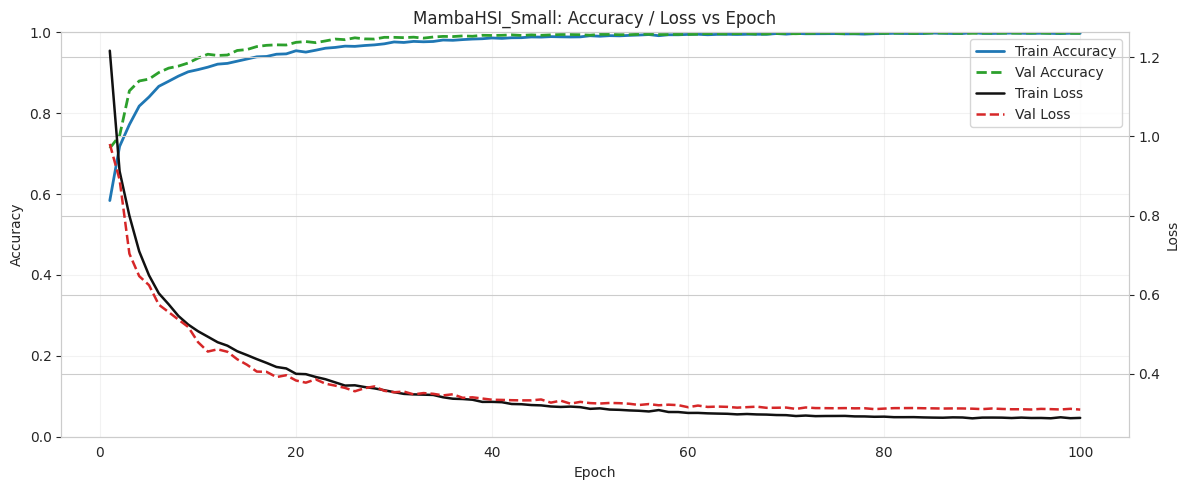

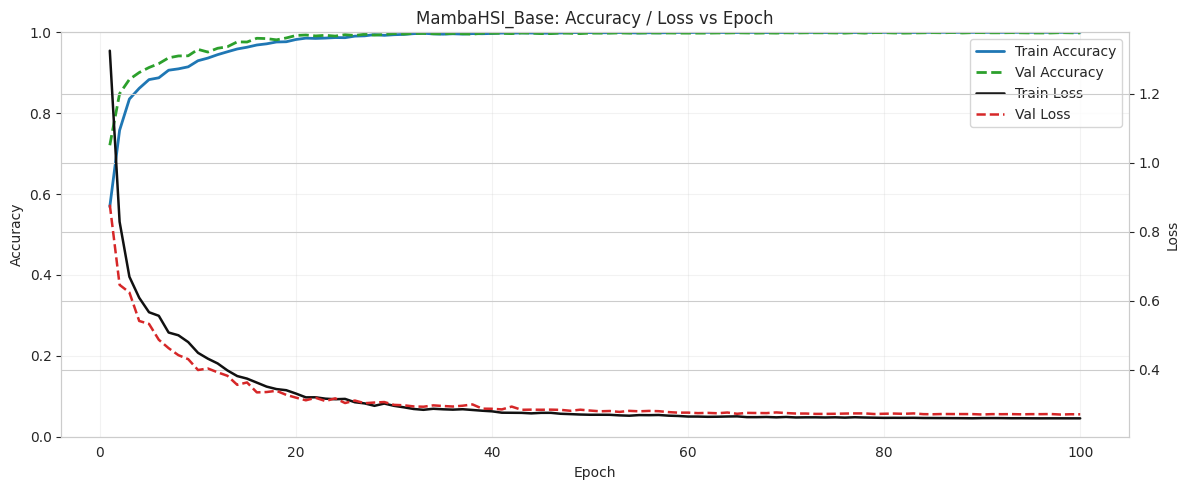

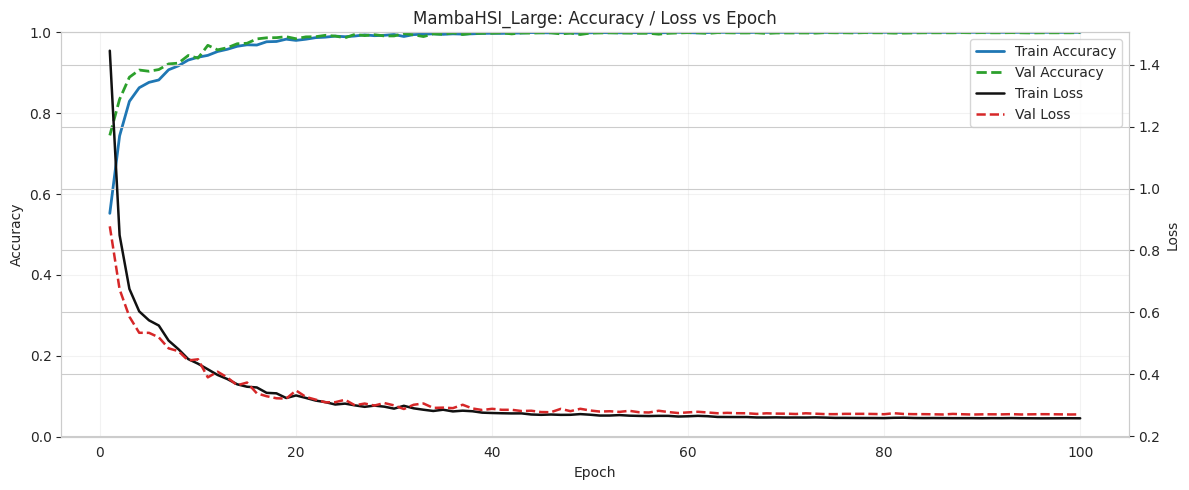

In [17]:
for model_name, artifact in model_artifacts.items():
    hist   = artifact["history"]
    epochs = np.arange(1, len(hist["loss"]) + 1)

    fig, ax1 = plt.subplots(figsize=(12, 5))
    ax1.plot(epochs, hist["accuracy"],     color="#1f77b4", linewidth=2,   label="Train Accuracy")
    ax1.plot(epochs, hist["val_accuracy"], color="#2ca02c", linewidth=2, linestyle="--", label="Val Accuracy")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Accuracy")
    ax1.set_ylim(0, 1.0)
    ax1.grid(True, alpha=0.25)

    ax2 = ax1.twinx()
    ax2.plot(epochs, hist["loss"],     color="#111111", linewidth=1.8,   label="Train Loss")
    ax2.plot(epochs, hist["val_loss"], color="#d62728", linewidth=1.8, linestyle="--", label="Val Loss")
    ax2.set_ylabel("Loss")

    lines  = ax1.get_lines() + ax2.get_lines()
    labels = [ln.get_label() for ln in lines]
    ax1.legend(lines, labels, loc="upper right", frameon=True)
    plt.title(f"{model_name}: Accuracy / Loss vs Epoch")
    plt.tight_layout()

    curve_path = PLOT_DIR / f"{model_name}_training_curves.png"
    plt.savefig(curve_path, dpi=200, bbox_inches="tight")
    plt.show()


## 7.3 — Cross-model comparison bar charts

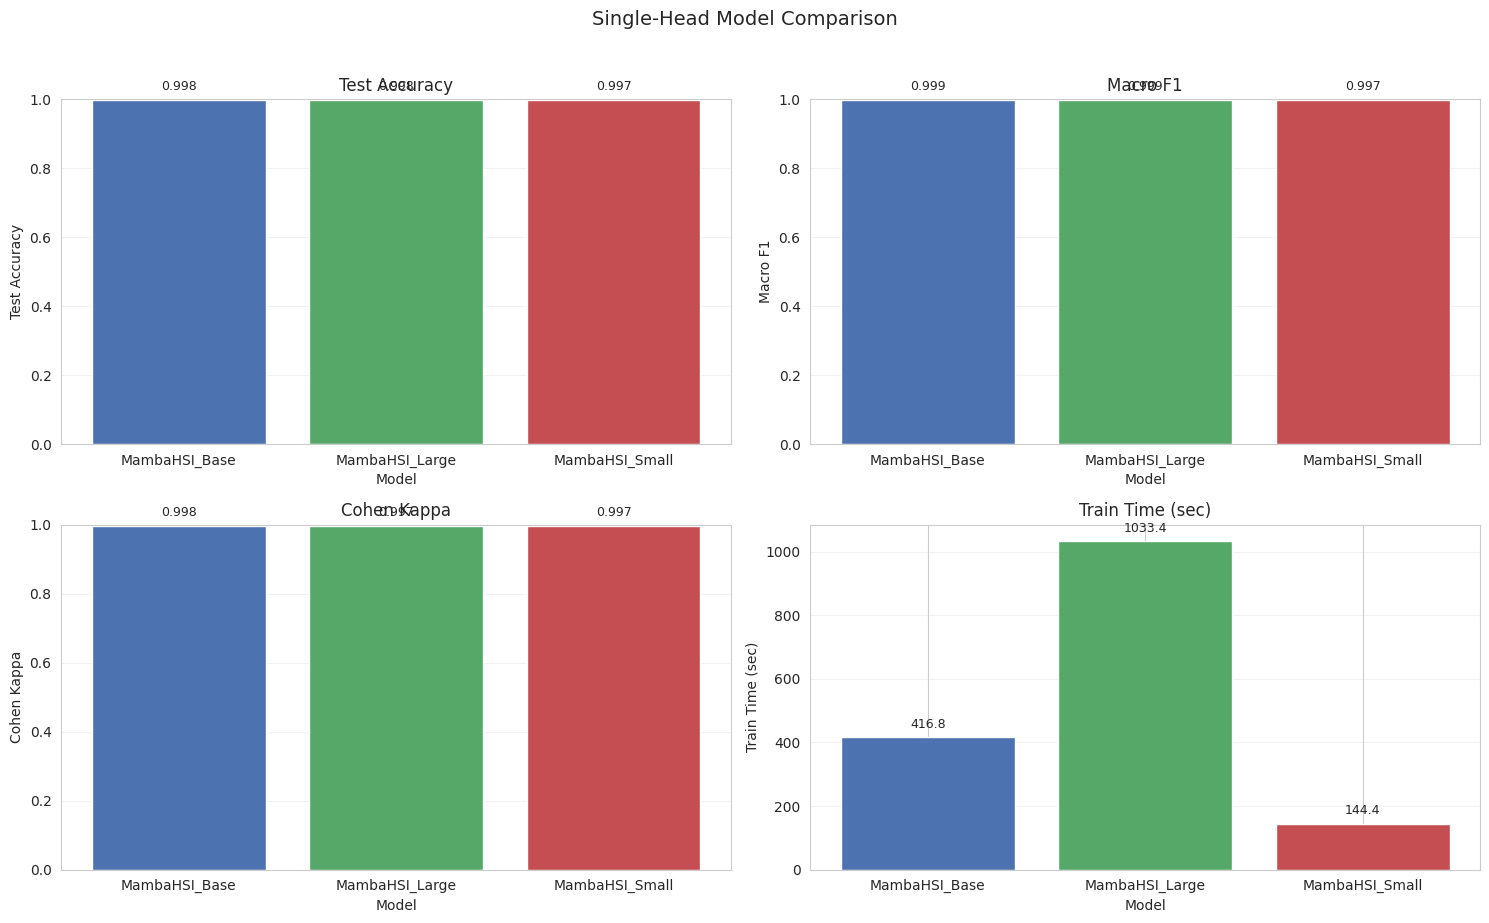

In [18]:
plot_df = summary_df[[
    "model", "test_accuracy", "macro_f1", "kappa", "train_time_sec",
    "test_nll", "test_brier", "test_ece_15bin",
]].copy()

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
axes    = axes.flatten()
palette = ["#4c72b0", "#55a868", "#c44e52"]

metric_specs = [
    ("test_accuracy",  "Test Accuracy",   (0.0, 1.0), "{:.3f}"),
    ("macro_f1",       "Macro F1",        (0.0, 1.0), "{:.3f}"),
    ("kappa",          "Cohen Kappa",     (0.0, 1.0), "{:.3f}"),
    ("train_time_sec", "Train Time (sec)", None,       "{:.1f}"),
]

for ax, (col, title, ylim, fmt) in zip(axes, metric_specs):
    local = plot_df[["model", col]].copy()
    bars  = ax.bar(local["model"], local[col], color=palette[:len(local)])
    ax.set_title(title)
    ax.set_xlabel("Model")
    ax.set_ylabel(title)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.grid(axis="y", alpha=0.25)
    for patch in bars:
        height = patch.get_height()
        xpos   = patch.get_x() + patch.get_width() / 2
        offset = (ylim[1] - ylim[0]) * 0.02 if ylim else max(local[col].max() * 0.02, 0.05)
        ax.text(xpos, height + offset, fmt.format(height), ha="center", va="bottom", fontsize=9)

plt.suptitle("Single-Head Model Comparison", y=1.02, fontsize=14)
plt.tight_layout()
comparison_path = PLOT_DIR / "model_comparison_metrics.png"
plt.savefig(comparison_path, dpi=200, bbox_inches="tight")
plt.show()


## 7.4 — Calibration proxy metrics and confusion matrices

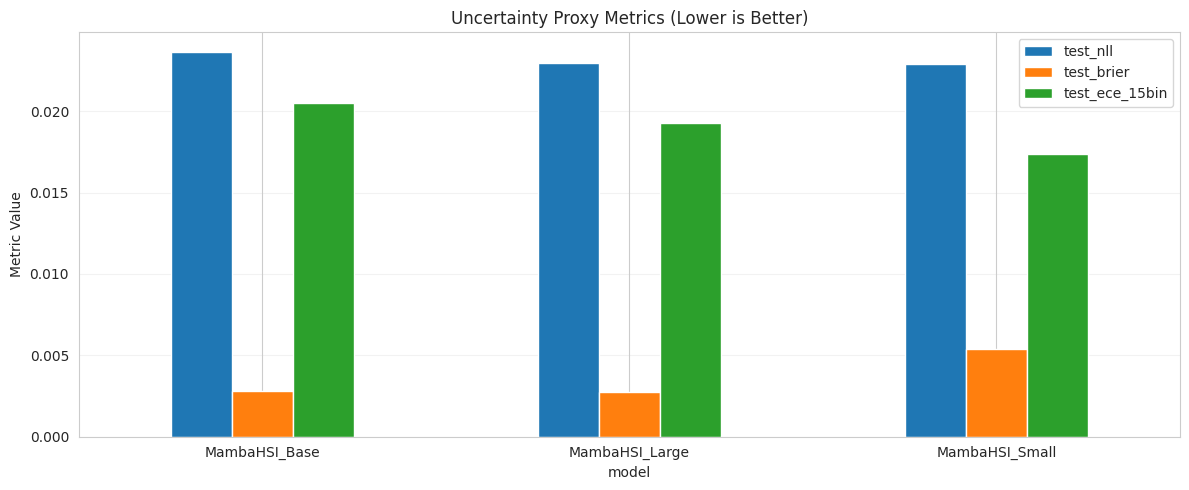

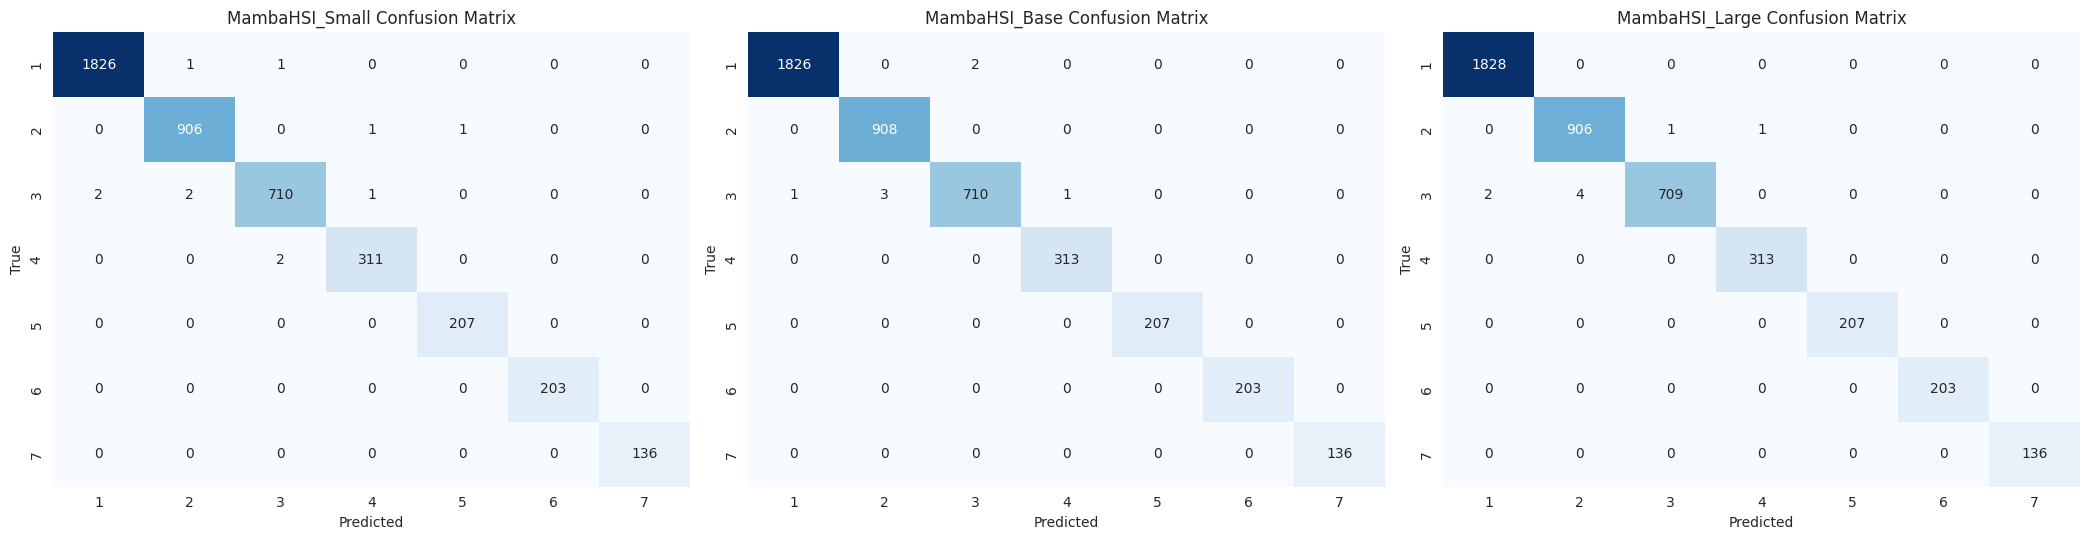

Saved confusion matrix figure: /content/drive/My Drive/Classification/mambahsi/results/training_plots/confusion_matrices_side_by_side.png
All training plots saved to: /content/drive/My Drive/Classification/mambahsi/results/training_plots


In [19]:
# Calibration proxy chart (lower is better for all three metrics)
fig, ax     = plt.subplots(figsize=(12, 5))
calib_cols  = ["test_nll", "test_brier", "test_ece_15bin"]
calib_df    = plot_df[["model"] + calib_cols].set_index("model")
calib_df.plot(kind="bar", ax=ax, rot=0)
ax.set_title("Uncertainty Proxy Metrics (Lower is Better)")
ax.set_ylabel("Metric Value")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
calib_path = PLOT_DIR / "uncertainty_proxy_metrics.png"
plt.savefig(calib_path, dpi=200, bbox_inches="tight")
plt.show()

# Side-by-side confusion matrices
class_ticks = [str(i + 1) for i in range(num_classes)]
fig, axes   = plt.subplots(1, len(model_artifacts), figsize=(7 * len(model_artifacts), 5.5))
if len(model_artifacts) == 1:
    axes = [axes]

for ax, (model_name, artifact) in zip(axes, model_artifacts.items()):
    sns.heatmap(
        artifact["confusion_matrix"],
        annot=True, fmt="d", cmap="Blues",
        xticklabels=class_ticks, yticklabels=class_ticks,
        cbar=False, ax=ax,
    )
    ax.set_title(f"{model_name} Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.tight_layout()
cm_path = PLOT_DIR / "confusion_matrices_side_by_side.png"
plt.savefig(cm_path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved confusion matrix figure:", cm_path)
print("All training plots saved to:", PLOT_DIR)


# 8.0 — Scene Visualisation
Load the saved best models, run dense patch-by-patch inference over the entire scene, and save classified maps as PNGs and an Excel workbook.

## 8.1 — Visualisation helpers

In [20]:
CUSTOM_OBJECTS = {
    "PatchExtractor":       PatchExtractor,
    "PatchPositionEncoder": PatchPositionEncoder,
    "SpectralScanLayer":    SpectralScanLayer,
    "SelectiveSSMBlock":    SelectiveSSMBlock,
}


def get_scene_rgb(x_img, bands):
    """Select three bands as an approximate RGB composite; clip to [0, 1]."""
    if bands >= 6:
        rgb_idx = [bands // 2 - 1, bands // 2, bands // 2 + 1]
    elif bands >= 3:
        rgb_idx = [0, 1, 2]
    else:
        raise ValueError(f"Need at least 3 bands to form RGB, got {bands}.")
    return np.clip(x_img[:, :, rgb_idx], 0.0, 1.0)


def get_display_cmap(num_classes):
    """Build a ListedColormap: index 0 = background black, 1..K = class colours."""
    return ListedColormap([BACKGROUND_COLOR] + CLASS_COLOR_BASE[:num_classes])


def predict_full_scene_labels(model, x_img, patch_size=9, batch_size=256):
    """Run dense sliding-window inference row-by-row; returns a (H, W) label map."""
    pad   = patch_size // 2
    x_pad = np.pad(x_img, ((pad, pad), (pad, pad), (0, 0)), mode="edge")
    preds = np.zeros((x_img.shape[0], x_img.shape[1]), dtype=np.int32)

    for r in range(x_img.shape[0]):
        row_patches = np.empty(
            (x_img.shape[1], patch_size, patch_size, x_img.shape[-1]),
            dtype=np.float32,
        )
        for c in range(x_img.shape[1]):
            row_patches[c] = x_pad[r:r + patch_size, c:c + patch_size, :]

        row_prob  = model.predict(row_patches, batch_size=batch_size, verbose=0)
        preds[r]  = np.argmax(row_prob, axis=1) + 1  # back to 1..K

    return preds


def load_saved_models_for_visualization(model_dir, custom_objects):
    """Attempt to load all three best models; return dicts of loaded and missing."""
    model_files = {
        "MambaHSI_Small": model_dir / "MambaHSI_Small_best.keras",
        "MambaHSI_Base":  model_dir / "MambaHSI_Base_best.keras",
        "MambaHSI_Large": model_dir / "MambaHSI_Large_best.keras",
    }
    loaded, missing = {}, {}
    for model_key, model_path in model_files.items():
        if not model_path.exists():
            missing[model_key] = f"Missing file: {model_path}"
            continue
        try:
            loaded[model_key] = keras.models.load_model(
                model_path, custom_objects=custom_objects,
                compile=False, safe_mode=False,
            )
        except Exception as exc:
            missing[model_key] = f"Load failed: {exc}"
    return loaded, missing


def save_single_panel(image, title, save_path, cmap=None, vmin=None, vmax=None):
    """Save a single image panel as a high-DPI PNG."""
    fig, ax = plt.subplots(figsize=(8, 6))
    if cmap is None:
        ax.imshow(image)
    else:
        ax.imshow(image, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=14)
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(save_path, dpi=220, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved:", save_path)


def save_combined_overview(rgb_image, y_true, pred_maps, missing_info, num_classes, save_path):
    """Save a five-panel side-by-side overview: RGB, GT, and one panel per model."""
    cmap   = get_display_cmap(num_classes)
    panels = [
        ("Approximate RGB",                    rgb_image,                       "rgb"),
        ("True Label Map",                     y_true,                          "label"),
        ("MambaHSI-Small Initial Classification", pred_maps.get("MambaHSI_Small"), "label"),
        ("MambaHSI-Base Initial Classification",  pred_maps.get("MambaHSI_Base"),  "label"),
        ("MambaHSI-Large Initial Classification", pred_maps.get("MambaHSI_Large"), "label"),
    ]

    fig, axes = plt.subplots(1, len(panels), figsize=(30, 7), sharex=True, sharey=True)
    for ax, (title, img, kind) in zip(axes, panels):
        ax.set_title(title, fontsize=13)
        if kind == "rgb":
            ax.imshow(img)
        elif img is None:
            ax.imshow(np.zeros_like(y_true), cmap=cmap, vmin=0, vmax=num_classes)
            key = {
                "MambaHSI-Small": "MambaHSI_Small",
                "MambaHSI-Base":  "MambaHSI_Base",
                "MambaHSI-Large": "MambaHSI_Large",
            }.get(
                next((k for k in ("MambaHSI-Small", "MambaHSI-Base", "MambaHSI-Large") if k in title), None)
            )
            ax.text(0.5, 0.5, missing_info.get(key, "Unavailable"),
                    ha="center", va="center", fontsize=10, wrap=True, transform=ax.transAxes)
        else:
            ax.imshow(img, cmap=cmap, vmin=0, vmax=num_classes)
        ax.axis("off")

    handles = [plt.Rectangle((0, 0), 1, 1, color=BACKGROUND_COLOR, label="Background")]
    for i in range(num_classes):
        handles.append(plt.Rectangle((0, 0), 1, 1, color=CLASS_COLOR_BASE[i], label=f"Class {i+1}"))
    fig.legend(handles=handles, loc="lower center", ncol=min(num_classes + 1, 8),
               bbox_to_anchor=(0.5, -0.02), frameon=True)
    fig.tight_layout(rect=[0, 0.05, 1, 1])
    fig.savefig(save_path, dpi=220, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved:", save_path)


def save_images_to_excel(excel_path, image_paths, sheet_name="Initial_Classification_Maps"):
    """Embed PNG images into an Excel workbook at fixed anchor positions."""
    if excel_path.exists():
        wb = load_workbook(excel_path)
        if sheet_name in wb.sheetnames:
            del wb[sheet_name]
        ws = wb.create_sheet(title=sheet_name)
    else:
        wb = Workbook()
        ws = wb.active
        ws.title = sheet_name

    anchors = ["A1", "J1", "A25", "J25", "A49", "J49"]
    for path, anchor in zip(image_paths, anchors):
        if path.exists():
            img        = XLImage(str(path))
            img.anchor = anchor
            ws.add_image(img)

    wb.save(excel_path)
    print("Saved Excel workbook:", excel_path)



## 8.2 — Generate and save all scene maps

In [21]:
scene_rgb    = get_scene_rgb(x_img, B)
display_cmap = get_display_cmap(num_classes)

loaded_models, missing_models = load_saved_models_for_visualization(MODEL_DIR, CUSTOM_OBJECTS)
prediction_maps = {}

for model_key, loaded_model in loaded_models.items():
    print(f"Generating full-scene classified image for {model_key}...")
    prediction_maps[model_key] = predict_full_scene_labels(
        loaded_model, x_img, patch_size=PATCH_SIZE, batch_size=BATCH_SIZE,
    )
    print(f"{model_key} map shape:", prediction_maps[model_key].shape)

if missing_models:
    print("Some models could not be loaded:")
    for model_key, reason in missing_models.items():
        print(f"  - {model_key}: {reason}")

# Individual PNG paths
rgb_png      = VIS_DIR / "scene_rgb.png"
gt_png       = VIS_DIR / "ground_truth_label_map.png"
small_png    = VIS_DIR / "MambaHSI_Small_initial_classification.png"
base_png     = VIS_DIR / "MambaHSI_Base_initial_classification.png"
large_png    = VIS_DIR / "MambaHSI_Large_initial_classification.png"
overview_png = VIS_DIR / "combined_initial_classification_overview.png"

save_single_panel(scene_rgb, "Approximate RGB", rgb_png)
save_single_panel(y_img, "Ground Truth Label Map", gt_png, cmap=display_cmap, vmin=0, vmax=num_classes)

if prediction_maps.get("MambaHSI_Small") is not None:
    save_single_panel(prediction_maps["MambaHSI_Small"], "MambaHSI-Small Initial Classification",
                      small_png, cmap=display_cmap, vmin=0, vmax=num_classes)

if prediction_maps.get("MambaHSI_Base") is not None:
    save_single_panel(prediction_maps["MambaHSI_Base"], "MambaHSI-Base Initial Classification",
                      base_png, cmap=display_cmap, vmin=0, vmax=num_classes)

if prediction_maps.get("MambaHSI_Large") is not None:
    save_single_panel(prediction_maps["MambaHSI_Large"], "MambaHSI-Large Initial Classification",
                      large_png, cmap=display_cmap, vmin=0, vmax=num_classes)

save_combined_overview(
    rgb_image=scene_rgb, y_true=y_img, pred_maps=prediction_maps,
    missing_info=missing_models, num_classes=num_classes, save_path=overview_png,
)

image_paths_for_excel = [rgb_png, gt_png, small_png, base_png, large_png, overview_png]
save_images_to_excel(VIS_EXCEL_PATH, image_paths_for_excel, sheet_name="Initial_Classification_Maps")

print("All visualisation outputs saved to:", VIS_DIR)



Output hidden; open in https://colab.research.google.com to view.